# CUSTOMER ANALYSIS

## BUSINESS CASE

### PERTANYAAN BUSINESS

1. Bagaimana distribusi pelanggan berdasarkan state dan kota di Brazil?
2. Berapa rata-rata nilai order per pelanggan dan bagaimana distribusinya?
3. Bagaimana pola aktivitas pembelian customer berdasarkan hari dan jam, dan apakah terdapat waktu tertentu dengan konsentrasi customer yang lebih tinggi?

### SCOPE ANALYSIS 

Q1 dan Q3 menggunakan seluruh data yang relevan tanpa membatasi berdasarkan order_status. Q2 menggunakan order dengan order_status = 'delivered' karena analisis AOV per customer berfokus pada order yang telah selesai.

## IMPORT LIBRARY

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import datetime

## GATHERING DATA

In [2]:
order = pd.read_csv('https://raw.githubusercontent.com/adinfir/data-new/refs/heads/main/E-commerce-public-dataset/orders_dataset.csv')
customer = pd.read_csv('https://raw.githubusercontent.com/adinfir/data-new/refs/heads/main/E-commerce-public-dataset/customers_dataset.csv')
order_items = pd.read_csv('https://raw.githubusercontent.com/adinfir/data-new/refs/heads/main/E-commerce-public-dataset/order_items_dataset.csv')

## DATA UNDERSTANDING

In [3]:
order.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
customer.head(5)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
order_items.head(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


### GRAIN

1. tabel order : 1 row merepresntasikan 1 order
2. tabel order_items : 1 row mempresentasikan item dalam sebuah order
3. tabel customer : 1 row mempresentasikan 1 pelanggan atau customer

### KEY COLUMNS

1. **Tabel `orders`**:
   - `order_id` → identifier untuk setiap order
   - `customer_id` → identifier customer digunakan untuk menghubungkan `order` dengan `customer`
   - `order_status` → status order
   - `order_purchase_timestamp` → waktu saat customer melakukan order

2. **Tabel `order_items`**:
   - `order_id` → identifier order, digunakan untuk menghubungkan `order_items` dengan `orders`
   - `price` → harga item

3. **Tabel `customer`**:
   - `customer_id` → identifier untuk setiap customer
   - `customer_unique_id` → ID yang merepresentasikan customer yang sebenarnya/unik
   - `customer_state` → state tiap customer
   - `customer_city` → city tiap customer

### RELATIONSHIP TABEL 


- Tabel `order` dan `order_items` terhubung melalui `order_id`.
- Tabel `order` dan `customer` terhubung melalui `customer_id`.

- `order` memiliki hubungan **one-to-many (1:N)** dengan `order_items`, karena satu order dapat memiliki beberapa item.
- `order` memiliki hubungan **many-to-one (N:1)** dengan `customer`, karena satu customer dapat memiliki beberapa order.

## DATA QUALITY

### ASESSING DATA

In [6]:
order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


 Kolom `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date` masih memiliki tipe data **object**, sehingga perlu dikonversi ke tipe **datetime** sebelum digunakan dalam analisis berbasis waktu_

In [7]:
order.describe(include='all')

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-04-11 10:48:14,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-08 23:38:46,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [8]:
print('Checking null value')
order.isna().sum()

Checking null value


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Pada kolom `order_approved_at`, `order_delivered_carrier_date`, dan `order_delivered_customer_date` terdapat **missing value** yang perlu ditangani sebelum dilakukan analisis lebih lanjut.

In [9]:
print('Checking duplicated value')
order.duplicated().sum()

Checking duplicated value


0

In [10]:
customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [11]:
customer.describe(include='all')

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
count,99441,99441,99441.000000,99441,99441
unique,99441,96096,NaN,4119,27
top,06b8999e2fba1a1fbc88172c00ba8bc7,8d50f5eadf50201ccdcedfb9e2ac8455,NaN,sao paulo,SP
freq,1,17,NaN,15540,41746
mean,NaN,NaN,35137.474583,NaN,NaN
std,NaN,NaN,29797.938996,NaN,NaN
min,NaN,NaN,1003.000000,NaN,NaN
25%,NaN,NaN,11347.000000,NaN,NaN
50%,NaN,NaN,24416.000000,NaN,NaN
75%,NaN,NaN,58900.000000,NaN,NaN


In [12]:
print('Checking null value')
customer.isna().sum()

Checking null value


customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [13]:
print('Checking duplicated value')
customer.duplicated().sum()

Checking duplicated value


0

In [14]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [15]:
order_items.describe(include='all')

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
count,112650,112650.000000,112650,112650,112650,112650.000000,112650.000000
unique,98666,NaN,32951,3095,93318,NaN,NaN
top,8272b63d03f5f79c56e9e4120aec44ef,NaN,aca2eb7d00ea1a7b8ebd4e68314663af,6560211a19b47992c3666cc44a7e94c0,2017-07-21 18:25:23,NaN,NaN
freq,21,NaN,527,2033,21,NaN,NaN
mean,NaN,1.197834,NaN,NaN,NaN,120.653739,19.990320
std,NaN,0.705124,NaN,NaN,NaN,183.633928,15.806405
min,NaN,1.000000,NaN,NaN,NaN,0.850000,0.000000
25%,NaN,1.000000,NaN,NaN,NaN,39.900000,13.080000
50%,NaN,1.000000,NaN,NaN,NaN,74.990000,16.260000
75%,NaN,1.000000,NaN,NaN,NaN,134.900000,21.150000


In [16]:
print('Checking null value')
order_items.isna().sum()

Checking null value


order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [17]:
print('Checking duplicated value')
order_items.duplicated().sum()

Checking duplicated value


0

### DATA CLEANNING

## DATA PREPARATION

### MENGUBAH TIPE DATA PADA TABEL ORDER

Mengubah kolom `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date` dari tipe data **object** menjadi **datetime** agar dapat digunakan dalam analisis berbasis waktu.


In [18]:
order['order_purchase_timestamp'] = pd.to_datetime(order['order_purchase_timestamp'])
order['order_approved_at'] = pd.to_datetime(order['order_approved_at'])
order['order_delivered_carrier_date'] = pd.to_datetime(order['order_delivered_carrier_date'])
order['order_delivered_customer_date'] = pd.to_datetime(order['order_delivered_customer_date'])
order['order_estimated_delivery_date'] = pd.to_datetime(order['order_estimated_delivery_date'])

### JOIN TABEL

In [19]:
# Join table order dan tabel customer
order_customer = pd.merge(
    left = order,
    right = customer,
    how = 'left',
    on = 'customer_id'
).reset_index()

In [20]:
# Join tabel order_customer dan order_itmes
order_customer_items = pd.merge(
    left = order_items,
    right = order_customer,
    how = 'left',
    on = 'order_id'
)

In [21]:
order_customer_items.isna().sum()

order_id                            0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
index                               0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  15
order_delivered_carrier_date     1194
order_delivered_customer_date    2454
order_estimated_delivery_date       0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
dtype: int64

**DATA QUALITY NOTE**
1. Terdapat missing value pada kolom  ```order_approved_at```, ```order_delivered_carrier_date```, ```order_delivered_customer_date```
2. Tidak dilakukan imputasi atau penghapusan missing value pada tahap ini karena kolom tersebut tidak digunakan dalam analisis Sales & Revenue.
3. Missing value tersebut menjadi keterbatasan data yang perlu diperhatikan apabila dataset digunakan untuk analisis terkait proses dan durasi pengiriman.

### MENAMBAH FEATURE HARI DAN JAM 

In [22]:
# Menambah feature hari
order_customer_items['hari'] = order_customer_items['order_purchase_timestamp'].dt.strftime("%A")

In [23]:
# Menambah feature jam
order_customer_items['jam'] = order_customer_items['order_purchase_timestamp'].dt.strftime("%H")

In [24]:
order_customer_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 21 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       112650 non-null  object        
 1   order_item_id                  112650 non-null  int64         
 2   product_id                     112650 non-null  object        
 3   seller_id                      112650 non-null  object        
 4   shipping_limit_date            112650 non-null  object        
 5   price                          112650 non-null  float64       
 6   freight_value                  112650 non-null  float64       
 7   index                          112650 non-null  int64         
 8   customer_id                    112650 non-null  object        
 9   order_status                   112650 non-null  object        
 10  order_purchase_timestamp       112650 non-null  datetime64[ns]
 11  

In [25]:
# Check duplicated data
order_customer_items.duplicated().sum()

0

In [26]:
# 1. Definisikan dictionary mapping dari singkatan ke nama lengkap
state_mapping = {
    'AC': 'Acre', 'AL': 'Alagoas', 'AM': 'Amazonas', 'AP': 'Amapá',
    'BA': 'Bahia', 'CE': 'Ceará', 'DF': 'Distrito Federal', 'ES': 'Espírito Santo',
    'GO': 'Goiás', 'MA': 'Maranhão', 'MG': 'Minas Gerais', 'MS': 'Mato Grosso do Sul',
    'MT': 'Mato Grosso', 'PA': 'Pará', 'PB': 'Paraíba', 'PE': 'Pernambuco',
    'PI': 'Piauí', 'PR': 'Paraná', 'RJ': 'Rio de Janeiro', 'RN': 'Rio Grande do Norte',
    'RO': 'Rondônia', 'RR': 'Roraima', 'RS': 'Rio Grande do Sul', 'SC': 'Santa Catarina',
    'SE': 'Sergipe', 'SP': 'São Paulo', 'TO': 'Tocantins'
}

# 2. Contoh penerapan pada DataFrame (misal: df_customers atau df_sellers)
# Ganti 'df' dengan nama variabel DataFrame Anda
# Kolom asal biasanya bernama 'customer_state' atau 'seller_state'
order_customer_items['state_full_name'] = order_customer_items['customer_state'].map(state_mapping)


## EXPLORATORY DATA ANALYSIS

### 1. Bagaimana distribusi pelanggan berdasarkan state dan kota di Brazil?

In [27]:
data_q1 = order_customer_items[['customer_unique_id','customer_city','state_full_name',]]

In [28]:
# Checking duplicated data
data_q1.duplicated().sum()

17111

#### DATA QUALITY NOTE

Duplicate ditemukan karena satu customer dapat memiliki beberapa order. Duplicate tidak dihapus untuk data utama karena Q1 menggunakan nunique() pada customer_unique_id, sehingga setiap customer tetap dihitung satu kali dalam agregasi.

In [29]:
# Agregasi Total customer berdasarkan state
data_q1_state = data_q1.groupby(['state_full_name'])['customer_unique_id'].nunique().reset_index().sort_values(by='customer_unique_id', ascending=False)
data_q1_state

,state_full_name,customer_unique_id
25,São Paulo,39981
20,Rio de Janeiro,12303
12,Minas Gerais,11178
19,Rio Grande do Sul,5249
13,Paraná,4840
23,Santa Catarina,3513
4,Bahia,3257
6,Distrito Federal,2062
7,Espírito Santo,1956
8,Goiás,1942


In [30]:
# Mengganti nama kolom
data_q1_state = data_q1_state.rename(columns={
    'customer_unique_id': 'Total Customer',
    'state_full_name' : 'customer_state'
    }
)
data_q1_state

,customer_state,Total Customer
25,São Paulo,39981
20,Rio de Janeiro,12303
12,Minas Gerais,11178
19,Rio Grande do Sul,5249
13,Paraná,4840
23,Santa Catarina,3513
4,Bahia,3257
6,Distrito Federal,2062
7,Espírito Santo,1956
8,Goiás,1942


In [31]:
# Agregasi Total customer berdasarkan state dan city
data_q1_state_city = data_q1.groupby(['state_full_name', 'customer_city'])['customer_unique_id'].nunique().reset_index().sort_values(by='customer_unique_id', ascending=False)
data_q1_state_city

,state_full_name,customer_city,customer_unique_id
4166,São Paulo,sao paulo,14865
3249,Rio de Janeiro,rio de janeiro,6576
1227,Minas Gerais,belo horizonte,2654
600,Distrito Federal,brasilia,2056
1997,Paraná,curitiba,1455
...,...,...,...
1764,Minas Gerais,santana do capivari,1
1765,Minas Gerais,santana do deserto,1
1771,Minas Gerais,santo antonio do aventureiro,1
3184,Rio de Janeiro,duas barras,1


In [32]:
# Mengganti nama kolom
data_q1_state_city = data_q1_state_city.rename(columns={
    'customer_unique_id': 'Total Customer',
    'state_full_name' : 'customer_state'
    }
)

In [33]:
# Menambah feature state + city
data_q1_state_city['State_city'] = data_q1_state_city['customer_city'] + '--' + data_q1_state_city['customer_state']

C:\Users\adien\AppData\Local\Temp\ipykernel_11140\569828174.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


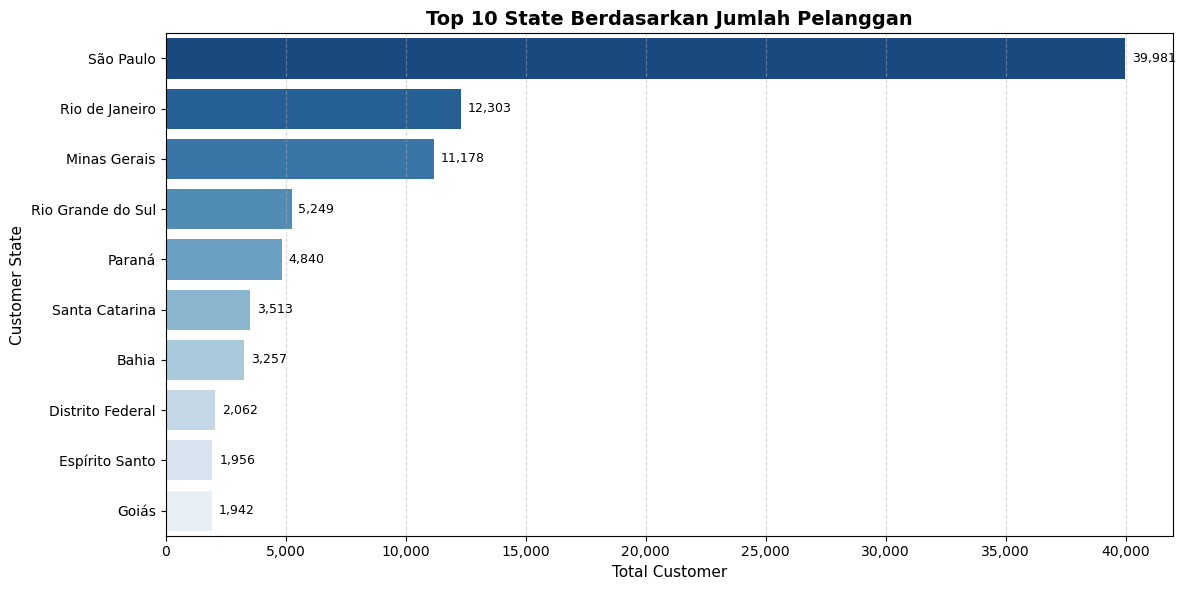

In [34]:
# Mengambil 10 state dengan jumlah pelanggan terbanyak
top_10_state = data_q1_state.head(10)

# Membuat horizontal bar chart
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_10_state,
    x='Total Customer',
    y='customer_state',
    palette='Blues_r'
)

# Menambahkan label jumlah pelanggan pada setiap batang
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='{:,.0f}',
        padding=5,
        fontsize=9
    )

# Memformat angka pada sumbu X dengan pemisah ribuan
ax.xaxis.set_major_formatter(
    ticker.StrMethodFormatter('{x:,.0f}')
)

# Menambahkan judul dan label sumbu
plt.title(
    'Top 10 State Berdasarkan Jumlah Pelanggan',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Total Customer', fontsize=11)
plt.ylabel('Customer State', fontsize=11)

# Menambahkan grid vertikal untuk memudahkan perbandingan
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

C:\Users\adien\AppData\Local\Temp\ipykernel_11140\1101572898.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


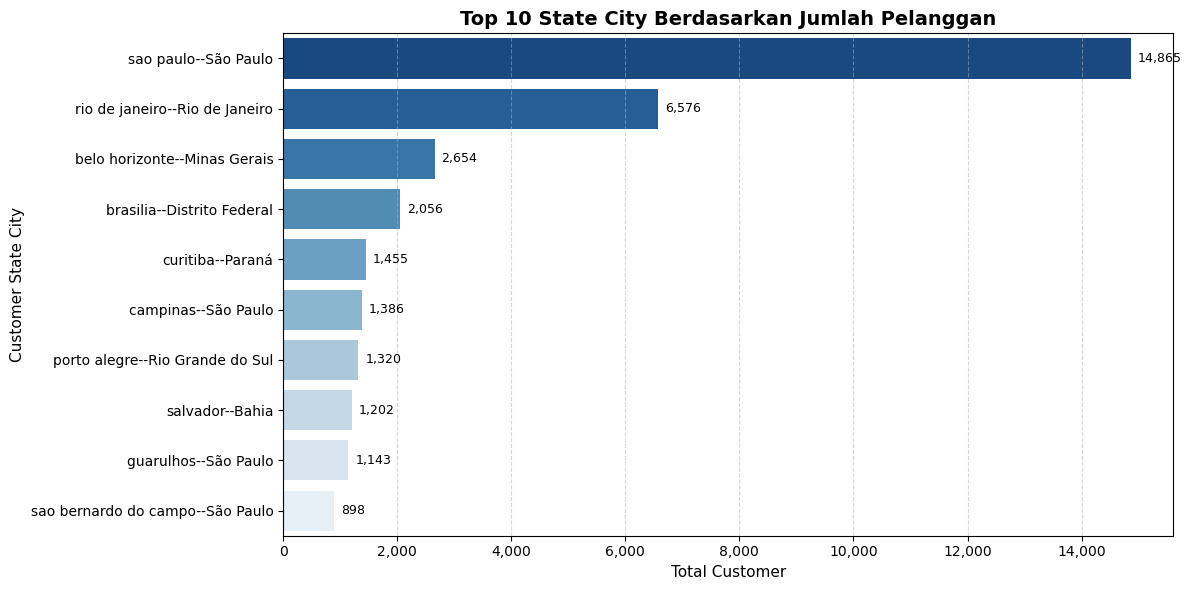

In [35]:
# Mengambil 10 state dengan jumlah pelanggan terbanyak
top_10_state_city = data_q1_state_city.head(10)

# Membuat horizontal bar chart
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_10_state_city,
    x='Total Customer',
    y='State_city',
    palette='Blues_r'
)

# Menambahkan label jumlah pelanggan pada setiap batang
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='{:,.0f}',
        padding=5,
        fontsize=9
    )

# Memformat angka pada sumbu X dengan pemisah ribuan
ax.xaxis.set_major_formatter(
    ticker.StrMethodFormatter('{x:,.0f}')
)

# Menambahkan judul dan label sumbu
plt.title(
    'Top 10 State City Berdasarkan Jumlah Pelanggan',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Total Customer', fontsize=11)
plt.ylabel('Customer State City', fontsize=11)

# Menambahkan grid vertikal untuk memudahkan perbandingan
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### KEY INSIGHT

1. State dengan total pelanggan terbanyak yaitu SP dengan total pelanggan 30.981, diikuti dengan RJ dengan total pelanggan 12.303
2. City dengan total pelanggan terbanyak yaitu Sao Paulo dengan total pelanggan 14.865, diiktui dengan Rio de Janeiro dengan total pelanggan 6.576

### 2. Berapa rata-rata nilai order per pelanggan dan bagaimana distribusinya?

In [36]:
data_q2 = order_customer_items[['customer_unique_id','order_status','price','order_id','order_item_id']]

In [37]:
# FIlter data berdasarkan order_status = delivered
data_q2 = data_q2[data_q2['order_status'] == 'delivered']

Filter Data: Analisis hanya menggunakan order dengan order_status = 'delivered' untuk memastikan perhitungan nilai order per pelanggan didasarkan pada transaksi yang telah berhasil diselesaikan.

In [38]:
# Check duplicate date
data_q2.duplicated().sum()

0

In [39]:
# Menghitung total nilai pembelian, jumlah order, dan jumlah item berdasarkan customer unik
data_q2_clean = data_q2.groupby('customer_unique_id').agg({
    'price': 'sum',
    'order_id': 'nunique',
    'order_item_id': 'count'
}).sort_values(
    by='price',
    ascending=False
).reset_index()

data_q2_clean

,customer_unique_id,price,order_id,order_item_id
0,0a0a92112bd4c708ca5fde585afaa872,13440.00,1,8
1,da122df9eeddfedc1dc1f5349a1a690c,7388.00,2,2
2,763c8b1c9c68a0229c42c9fc6f662b93,7160.00,1,4
3,dc4802a71eae9be1dd28f5d788ceb526,6735.00,1,1
4,459bef486812aa25204be022145caa62,6729.00,1,1
...,...,...,...,...
93353,cf3839da0d9492ad151690b65f45d800,2.99,1,1
93354,bd06ce0e06ad77a7f681f1a4960a3cc6,2.29,1,1
93355,317cfc692e3f86c45c95697c61c853a6,2.20,1,1
93356,b38211bd797f4fdd81a98b9d1754b606,0.85,1,1


In [40]:
# Mengganti nama kolom
data_q2_clean = data_q2_clean.rename(columns={
    'customer_unique_id': 'Nama Pelanggan',
    'order_id' : 'total order',
    'order_item_id' : 'total item dibeli'
    }
)
data_q2_clean

,Nama Pelanggan,price,total order,total item dibeli
0,0a0a92112bd4c708ca5fde585afaa872,13440.00,1,8
1,da122df9eeddfedc1dc1f5349a1a690c,7388.00,2,2
2,763c8b1c9c68a0229c42c9fc6f662b93,7160.00,1,4
3,dc4802a71eae9be1dd28f5d788ceb526,6735.00,1,1
4,459bef486812aa25204be022145caa62,6729.00,1,1
...,...,...,...,...
93353,cf3839da0d9492ad151690b65f45d800,2.99,1,1
93354,bd06ce0e06ad77a7f681f1a4960a3cc6,2.29,1,1
93355,317cfc692e3f86c45c95697c61c853a6,2.20,1,1
93356,b38211bd797f4fdd81a98b9d1754b606,0.85,1,1


In [41]:
# Menambah feature aov customer
data_q2_clean['aov_customer'] = (data_q2_clean['price'] / data_q2_clean['total order'] *100).round(2)
data_q2_clean.sort_values(by='aov_customer', ascending=False)

,Nama Pelanggan,price,total order,total item dibeli,aov_customer
0,0a0a92112bd4c708ca5fde585afaa872,13440.00,1,8,1344000.0
2,763c8b1c9c68a0229c42c9fc6f662b93,7160.00,1,4,716000.0
3,dc4802a71eae9be1dd28f5d788ceb526,6735.00,1,1,673500.0
4,459bef486812aa25204be022145caa62,6729.00,1,1,672900.0
5,ff4159b92c40ebe40454e3e6a7c35ed6,6499.00,1,1,649900.0
...,...,...,...,...,...
93353,cf3839da0d9492ad151690b65f45d800,2.99,1,1,299.0
93354,bd06ce0e06ad77a7f681f1a4960a3cc6,2.29,1,1,229.0
93355,317cfc692e3f86c45c95697c61c853a6,2.20,1,1,220.0
93356,b38211bd797f4fdd81a98b9d1754b606,0.85,1,1,85.0


C:\Users\adien\AppData\Local\Temp\ipykernel_11140\2241105858.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


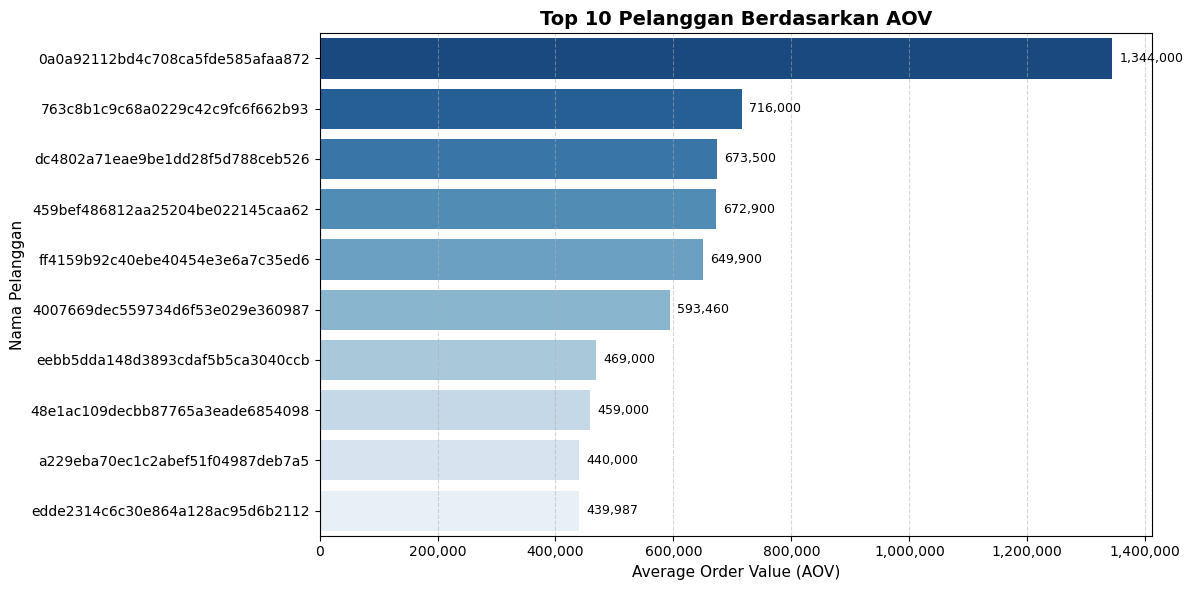

In [42]:
# Mengambil 10 pelanggan dengan AOV tertinggi
top_10_aov_cust = data_q2_clean.sort_values(
    by='aov_customer',
    ascending=False
).head(10)

# Membuat horizontal bar chart
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_10_aov_cust,
    x='aov_customer',
    y='Nama Pelanggan',
    palette='Blues_r'
)

# Menambahkan label AOV pada setiap batang
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='{:,.0f}',
        padding=5,
        fontsize=9
    )

# Memformat angka pada sumbu X dengan pemisah ribuan
ax.xaxis.set_major_formatter(
    ticker.StrMethodFormatter('{x:,.0f}')
)

# Menambahkan judul dan label sumbu
plt.title(
    'Top 10 Pelanggan Berdasarkan AOV',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Average Order Value (AOV)', fontsize=11)
plt.ylabel('Nama Pelanggan', fontsize=11)

# Menambahkan grid vertikal untuk memudahkan perbandingan
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### KEY INSIGHT

1. pelanggan dengan unique_id 0a0a92112bd4c708ca5fde585afaa872 memiliki average order value(AOV) tertinggi yaitu sebesar ```R$1.344.000,0``` 
2. pelanggan dengan unique_id 763c8b1c9c68a0229c42c9fc6f662b93 memiliki average order value(AOV) tertinggi kedua yaitu sebesar ```R$716.000```

### 3.Bagaimana pola aktivitas pembelian customer berdasarkan hari dan jam, dan apakah terdapat waktu tertentu dengan konsentrasi customer yang lebih tinggi? 

In [43]:
data_q3 = order_customer_items[['customer_unique_id','hari','jam']]

In [44]:
# Menambahkan feature hari dan jam 
data_q3['day & hour'] = data_q3['hari'] + ' ' + data_q3['jam']

C:\Users\adien\AppData\Local\Temp\ipykernel_11140\1797146425.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_q3['day & hour'] = data_q3['hari'] + ' ' + data_q3['jam']


In [45]:
# Check duplicated data
data_q3.duplicated().sum()

14911

**CATATAN** : Tidak dilakukan penanganan drop duplicated dikarenakan memiliki order_id dan order_item_id yang berbeda

In [46]:
# Mengganti nama kolom
data_q3 = data_q3.rename(columns={
    'customer_unique_id': 'Total Pelanggan',
    }
)

In [47]:
data_q3_hour = data_q3.groupby('jam')['Total Pelanggan'].nunique().reset_index()
data_q3_day = data_q3.groupby('hari')['Total Pelanggan'].nunique().reset_index()
data_q3_day_hour = data_q3.groupby('day & hour')['Total Pelanggan'].nunique().reset_index() 

In [48]:
data_q3_hour

,jam,Total Pelanggan
0,00,2345
1,01,1144
2,02,497
3,03,266
4,04,201
5,05,183
6,06,494
7,07,1213
8,08,2901
9,09,4673


In [49]:
data_q3_day_hour.sort_values(by='Total Pelanggan', ascending=False)

,day & hour,Total Pelanggan
134,Tuesday 14,1109
45,Monday 21,1103
40,Monday 16,1078
38,Monday 14,1076
136,Tuesday 16,1071
...,...,...
52,Saturday 04,25
125,Tuesday 05,24
53,Saturday 05,23
29,Monday 05,22


In [50]:
data_q3_clean = data_q3[['Total Pelanggan', 'hari', 'jam']]

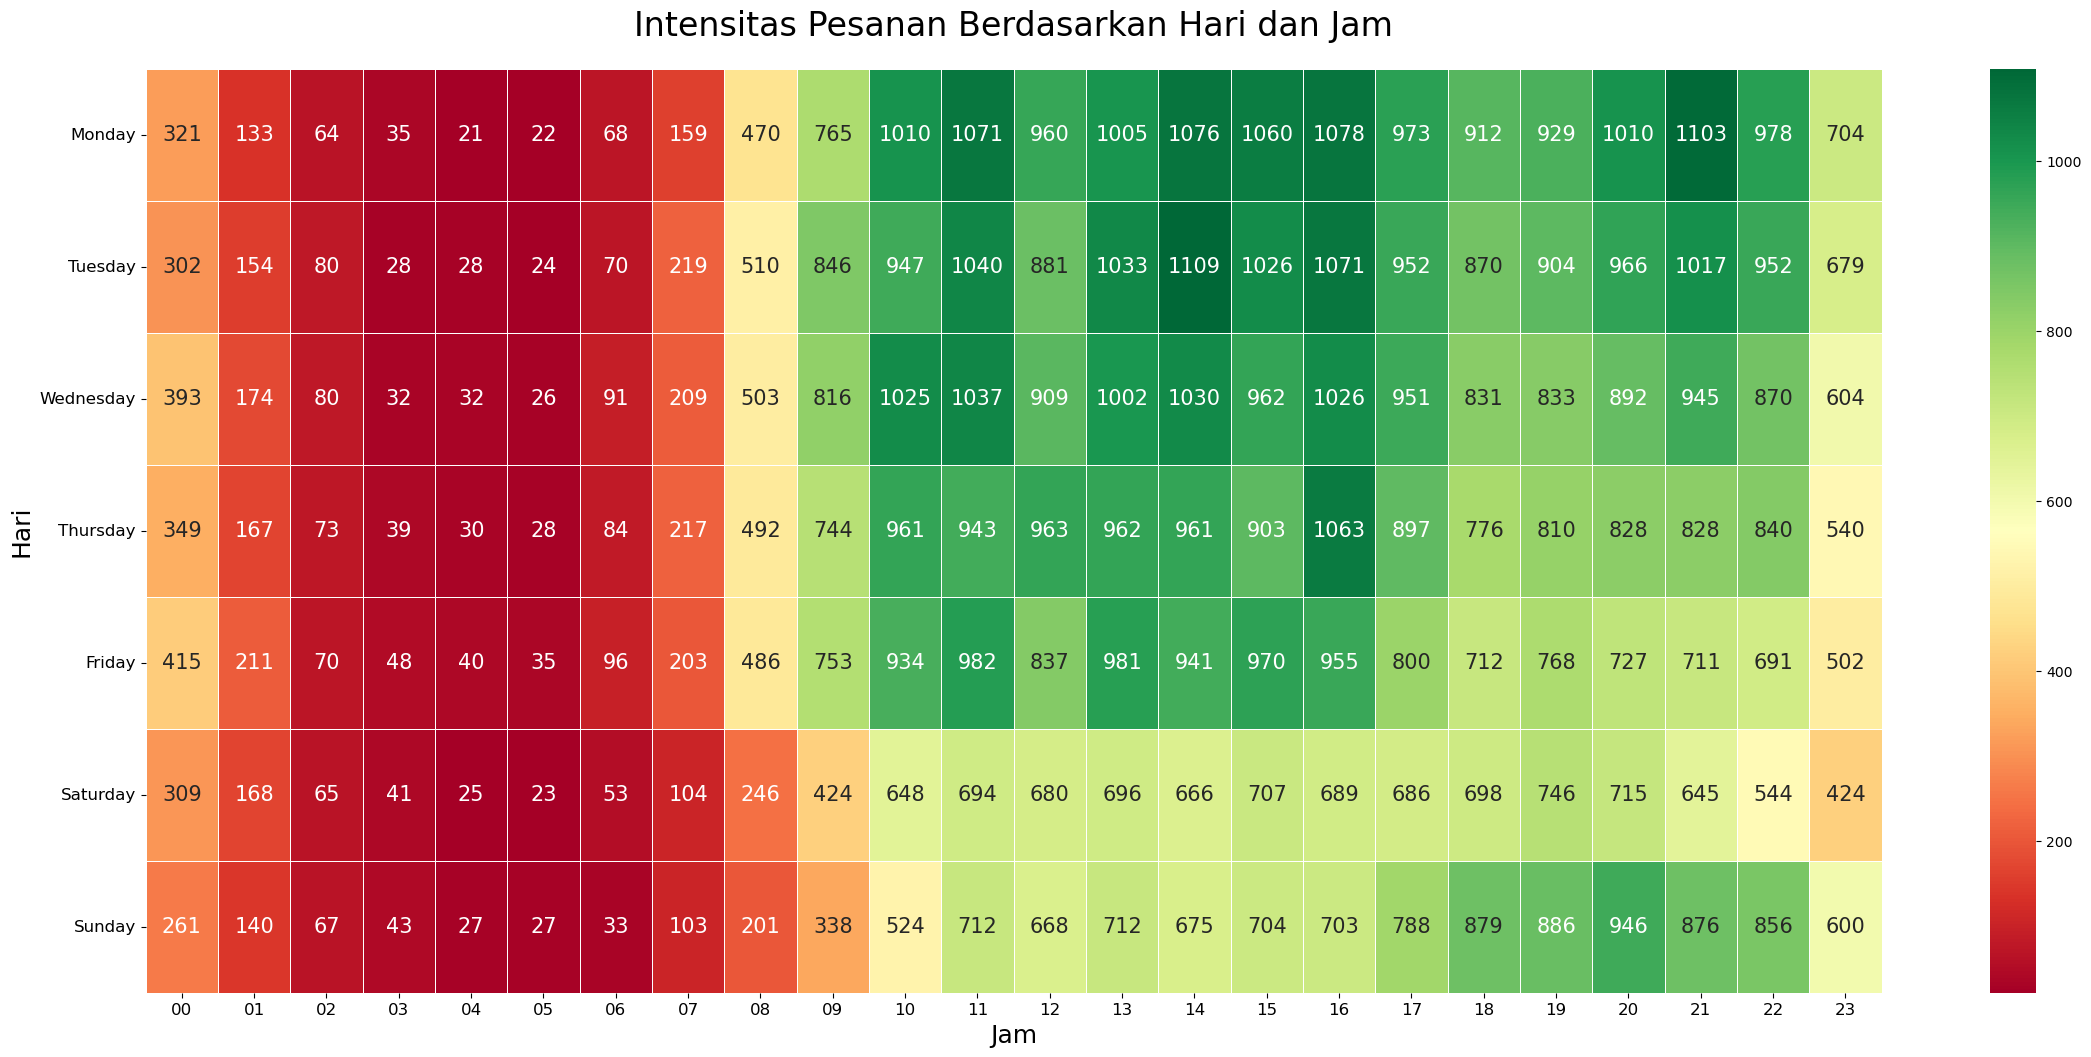

In [51]:

# 1. PERSIAPAN DATA: Menghitung jumlah pesanan (baris = hari, kolom = jam)
# pd.crosstab otomatis akan menghitung jumlah kemunculan untuk setiap kombinasi hari dan jam
order_activity_dayhour_crosstab = pd.crosstab(
    index=data_q3_clean['hari'], 
    columns=data_q3_clean['jam'],
    values=data_q3_clean['Total Pelanggan'], 
    aggfunc='nunique'
).fillna(0)

# (Opsional) Mengurutkan hari agar tampil berurutan dari Senin s.d. Minggu
# Perhatikan isi data Anda. Jika menggunakan bahasa Inggris (karena error sebelumnya menyebutkan 'Friday'):
urutan_hari = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
# Jika menggunakan bahasa Indonesia: ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']

# Terapkan urutan indeks
order_activity_dayhour_crosstab = order_activity_dayhour_crosstab.reindex(urutan_hari)


# 2. MEMBUAT HEATMAP
plt.figure(figsize=(28, 12)) # Mengatur ukuran grafik (lebar 14, tinggi 6)

sns.heatmap(
    order_activity_dayhour_crosstab, 
    annot=True,       # Menampilkan angka di dalam setiap kotak
    fmt='.0f',        # Format angka bulat (tanpa desimal). Gunakan 'd' jika dipastikan tidak ada nilai kosong (NaN)
    cmap='RdYlGn',  # Pilihan warna transisi dari hangat (oranye/kuning) ke sejuk (hijau/biru)
    linewidths=0.5,
    annot_kws={'size': 15},  # Membesarkan angka di dalam kotak
)

# Menambahkan judul dan label
plt.title('Intensitas Pesanan Berdasarkan Hari dan Jam', fontsize=24, pad=24)
plt.xlabel('Jam', fontsize=18)
plt.ylabel('Hari', fontsize=18)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12, rotation=0)  # rotation=0 agar nama hari tetap mendatar

# Menampilkan grafik
plt.show()

#### KEY INSIGHT

1. Aktivitas pelanggan yang melakukan tertinggi berdasarkan jam terjadi pada **pukul 16.00**, dengan total **6.575 pelanggan**.
2. Aktivitas pelanggan yang melakukan tertinggi berdasarkan hari terjadi pada **Monday**, dengan total **15.852 pelanggan**.
3. Aktivitas pelanggan yang melakukan tertinggi berdasarkan kombinasi hari dan jam terjadi pada **Tuesday pukul 14.00**, dengan total **1.109 pelanggan**.

## KEY FINDINGS

1. **State dengan jumlah pelanggan terbanyak** adalah **SP** dengan **30.981 pelanggan**, diikuti oleh **RJ** dengan **12.303 pelanggan**
2. **City dengan jumlah pelanggan terbanyak** adalah **São Paulo** dengan **14.865 pelanggan**, diikuti oleh **Rio de Janeiro** dengan **6.576 pelanggan** 
3. Pelanggan dengan `customer_unique_id` **0a0a92112bd4c708ca5fde585afaa872** memiliki **Average Order Value (AOV) tertinggi**, yaitu sebesar ``R$1.344.000,0``.
4. Pelanggan dengan `customer_unique_id` **763c8b1c9c68a0229c42c9fc6f662b93** memiliki **AOV tertinggi kedua**, yaitu sebesar ``R$716.000``.
5. **Aktivitas pelanggan yang melakukan tertinggi berdasarkan jam** terjadi pada **pukul 16.00**, dengan total **6.575 pelanggan**.
6. **Aktivitas pelanggan yang melakukan tertinggi berdasarkan hari** terjadi pada **Monday**, dengan total **15.852 pelanggan**.
7. **Aktivitas pelanggan yang melakukan tertinggi berdasarkan kombinasi hari dan jam** terjadi pada **Tuesday pukul 14.00**, dengan total **1.109 pelanggan**.


## BUSINESS IMPLICATIONS

1. **Prioritize key customer markets**
   São Paulo dan Rio de Janeiro memiliki basis pelanggan terbesar, sehingga dapat menjadi fokus dalam strategi customer acquisition dan engagement.

2. **Identify opportunities from high-AOV customers**
   Pelanggan dengan AOV tinggi dapat menjadi referensi untuk memahami pola transaksi bernilai tinggi dan mendukung strategi peningkatan customer value.

3. **Align operations with peak order periods**
   Tingginya aktivitas pelanggan melakukan order pada pukul 16.00 dan hari Monday dapat menjadi pertimbangan dalam perencanaan operasional dan resource allocation.

4. **Optimize timing based on day-hour patterns**
   Pola aktivitas berdasarkan kombinasi hari dan jam dapat digunakan untuk menentukan waktu yang lebih tepat dalam perencanaan campaign maupun kesiapan operasional.


In [52]:
order_customer_items

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,index,customer_id,order_status,...,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,hari,jam,state_full_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,85267,3ce436f183e68e07877b285a838db11a,delivered,...,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,Wednesday,08,Rio de Janeiro
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,71853,f6dd3ec061db4e3987629fe6b26e5cce,delivered,...,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,Wednesday,10,São Paulo
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6298,6489ae5e4333f3693df5ad4372dab6d3,delivered,...,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,Sunday,14,Minas Gerais
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,22550,d4eb9395c8c0431ee92fce09860c5a06,delivered,...,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,Wednesday,10,São Paulo
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,5247,58dbd0b2d70206bf40e62cd34e84d795,delivered,...,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,Saturday,13,São Paulo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,79550,b51593916b4b8e0d6f66f2ae24f2673d,delivered,...,2018-04-25 12:09:00,2018-05-10 22:56:40,2018-05-18,0c9aeda10a71f369396d0c04dce13a64,65077,sao luis,MA,Monday,13,Maranhão
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,70155,84c5d4fbaf120aae381fad077416eaa0,delivered,...,2018-07-17 08:05:00,2018-07-23 20:31:55,2018-08-01,0da9fe112eae0c74d3ba1fe16de0988b,81690,curitiba,PR,Saturday,10,Paraná
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,52699,29309aa813182aaddc9b259e31b870e6,delivered,...,2017-10-26 15:13:14,2017-10-28 12:22:22,2017-11-10,cd79b407828f02fdbba457111c38e4c4,4039,sao paulo,SP,Monday,17,São Paulo
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,59871,b5e6afd5a41800fdf401e0272ca74655,delivered,...,2017-08-15 19:02:53,2017-08-16 21:59:40,2017-08-25,eb803377c9315b564bdedad672039306,13289,vinhedo,SP,Monday,23,São Paulo


In [53]:
order_customer_items.to_excel("data.xlsx", index=False)